Se realizo el analisis exploratorio de los datos ates de realizar la limpieza para definir una ruta para el tratamiento de los mismos.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

RUTA_CSV = "/gastptoanual_2024_12.csv"

def extraer_y_analizar():
    print("=" * 60)
    print(" INICIANDO EXTRACCIÓN Y DIAGNÓSTICO DE DATOS ")
    print("=" * 60)

    # 1. Validación de existencia
    if not os.path.exists(RUTA_CSV):
        print(f"[ERROR] No se encuentra el archivo: {RUTA_CSV}")
        print("Asegúrate de que el nombre del archivo en el explorador coincida exactamente.")
        return

    # 2. Carga adaptativa del archivo CSV
    df = None
    # Intentaremos combinaciones comunes de codificación y separadores
    intentos = [
        {'encoding': 'utf-8', 'sep': ','},
        {'encoding': 'utf-8', 'sep': ';'},
        {'encoding': 'latin1', 'sep': ';'},
        {'encoding': 'latin1', 'sep': ','}
    ]

    for intento in intentos:
        try:
            df = pd.read_csv(RUTA_CSV, encoding=intento['encoding'], sep=intento['sep'])
            # Si se lee con un solo campo, posiblemente el separador sigue mal
            if df.shape[1] == 1 and intento['sep'] == ',':
                continue
            print(f"[ÉXITO] Archivo cargado correctamente usando codificación '{intento['encoding']}' y separador '{intento['sep']}'.")
            break
        except (UnicodeDecodeError, pd.errors.ParserError):
            continue

    if df is None:
        # Si fallan los intentos automáticos, intentamos con detección automática de separador
        try:
            df = pd.read_csv(RUTA_CSV, encoding='latin1', sep=None, engine='python')
            print("[ÉXITO] Archivo cargado mediante motor python y detección automática de separador.")
        except Exception as e:
            print(f"[ERROR] No se pudo procesar el archivo CSV: {e}")
            return

    # =========================================================================
    # EJECUCIÓN DE TUS SENTENCIAS DE DIAGNÓSTICO EN CONSOLA
    # =========================================================================

    print("\n🔹 1. INFORMACIÓN GENERAL (df.info()):")
    df.info()

    print("\n🔹 2. DIMENSIONES (df.shape - Filas, Columnas):")
    print(df.shape)

    print("\n🔹 3. TAMAÑO TOTAL DE CELDAS (df.size):")
    print(df.size)

    print("\n🔹 4. LISTADO DE COLUMNAS (df.columns):")
    print(df.columns)

    print("\n🔹 5. PRIMEROS REGISTROS (df.head(5)):")
    print(df.head(5))

    print("\n🔹 6. ÚLTIMOS REGISTROS (df.tail(5)):")
    print(df.tail(5))

    print("\n🔹 7. RANGO DEL ÍNDICE (df.index):")
    print(df.index)

    print("\n🔹 8. TIPOS DE DATOS POR COLUMNA (df.dtypes):")
    print(df.dtypes)

    print("\n" + "=" * 60)
    print(" DIAGNÓSTICO FINALIZADO CON ÉXITO ")
    print("=" * 60)

if __name__ == "__main__":
    extraer_y_analizar()

    print("\n" + "=" * 60)
    print("INICIANDO LIMPIEZA DE DATOS")
    print("=" * 60)




 INICIANDO EXTRACCIÓN Y DIAGNÓSTICO DE DATOS 
[ÉXITO] Archivo cargado correctamente usando codificación 'latin1' y separador ';'.

🔹 1. INFORMACIÓN GENERAL (df.info()):
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13772 entries, 0 to 13771
Data columns (total 20 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Vigencia                  13769 non-null  object
 1   Tipo de entidad           13769 non-null  object
 2   Codigo Entidad            13769 non-null  object
 3   Nombre de la Entidad      13769 non-null  object
 4   Programa de financiación  13769 non-null  object
 5   Descripcion del Programa  13769 non-null  object
 6   Código Rubro              13769 non-null  object
 7   Descripción Rubro         13769 non-null  object
 8   Enero                     8551 non-null   object
 9   Febrero                   8640 non-null   object
 10  Marzo                     8730 non-null   object
 11  Abril          

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

se realiza la transformacion de los datos en las colmnas de meses que tienen datos numericos en pesos pero al haber datos nulos (NAN) los pasamos  "0" y los asignamos a (INT). tambien se realiza el cambio de los separadores y se unifican para que queden separados por ";" se identifican los duplicados y se eliminan, se eliminan espacios en blanco y se coloca la primera letra en mayuscula para evitar inconsistencias.

In [ ]:
import pandas as pd
import numpy as np
import io

try:
    # Cambiado a encoding='latin1' para soportar los caracteres especiales del archivo plano
    df = pd.read_csv('/content/gastptoanual_2024_12.csv', sep=';', encoding='latin1')
    print("✅ Archivo cargado correctamente.")
except FileNotFoundError:
    print("❌ Archivo no encontrado. Asegúrate de cargarlo en el panel izquierdo de Colab y verificar la ruta.")

print(f"\nDimensiones iniciales del dataset: {df.shape[0]} filas y {df.shape[1]} columnas.")

# Eliminación de Duplicados
duplicados_antes = df.duplicated().sum()
df.drop_duplicates(inplace=True)
print(f" Se eliminaron {duplicados_antes} filas duplicadas exactas.")

# Limpieza y estandarización de columnas de texto
columnas_texto = ['Tipo de entidad', 'Nombre de la Entidad', 'Programa de financiación', 'Descripcion del Programa', 'Descripción Rubro']
for col in columnas_texto:
    if col in df.columns:
        df[col] = df[col].astype(str).str.strip().str.upper()

# Ajuste de Tipos de Datos e Identificación de Nulos
df['Código Rubro'] = df['Código Rubro'].astype(str).str.strip()
df['Codigo Entidad'] = df['Codigo Entidad'].astype(str).str.strip()

# Tratamiento específico para el campo 'Vigencia' (Formatos Año-Mes)
if 'Vigencia' in df.columns:
    df['Vigencia'] = df['Vigencia'].astype(str).str.strip()

# Tratamiento y Conversión de Columnas Mensuales (Formatos Numéricos)
meses = ['Enero', 'Febrero', 'Marzo', 'Abril', 'Mayo', 'Junio', 'Julio', 'Agosto', 'Septiembre', 'Octubre', 'Noviembre', 'Diciembre']

for mes in meses:
    if mes in df.columns:
        # Tratamiento de nulos en meses: En presupuestos, un espacio vacío significa ejecución cero ($0)
        df[mes] = df[mes].fillna('0')

        # Convertimos a string, limpiamos espacios, eliminamos los puntos de miles y reemplazamos por formato limpio
        df[mes] = df[mes].astype(str).str.strip()
        df[mes] = df[mes].str.replace('.', '', regex=False)
        df[mes] = df[mes].str.replace(',', '.', regex=False)
        df[mes] = pd.to_numeric(df[mes], errors='coerce').fillna(0).astype(int)

# Diagnóstico de Nulos Finales en Columnas
print("\n🔍 Verificación final de valores nulos por columna:")
print(df.isnull().sum())


print(f"\nDimensiones finales del dataset limpio: {df.shape[0]} filas y {df.shape[1]} columnas.")
print("\n📋 Primeras 3 filas del dataset limpio:")
print(df.head(3))

# Exportar los datos limpios
df.to_csv('datos_presupuesto_limpios.csv', sep=';', index=False, encoding='utf-8')
print("\n💾 Archivo 'datos_presupuesto_limpios.csv' guardado y listo para descargar.")

✅ Archivo cargado correctamente.

Dimensiones iniciales del dataset: 13772 filas y 20 columnas.
 Se eliminaron 2 filas duplicadas exactas.

🔍 Verificación final de valores nulos por columna:
Vigencia                    0
Tipo de entidad             1
Codigo Entidad              0
Nombre de la Entidad        0
Programa de financiación    0
Descripcion del Programa    0
Código Rubro                0
Descripción Rubro           1
Enero                       0
Febrero                     0
Marzo                       0
Abril                       0
Mayo                        0
Junio                       0
Julio                       0
Agosto                      0
Septiembre                  0
Octubre                     0
Noviembre                   0
Diciembre                   0
dtype: int64

Dimensiones finales del dataset limpio: 13770 filas y 20 columnas.

📋 Primeras 3 filas del dataset limpio:
  Vigencia        Tipo de entidad  Codigo Entidad    Nombre de la Entidad  \
0  2024-12

Se realiza el carge del dataset ya limpio y se procede a realizar el EDA generando tres graficos que nos puedan dar mayor informacion de los datos.

✅ Dataset cargado correctamente para el EDA.


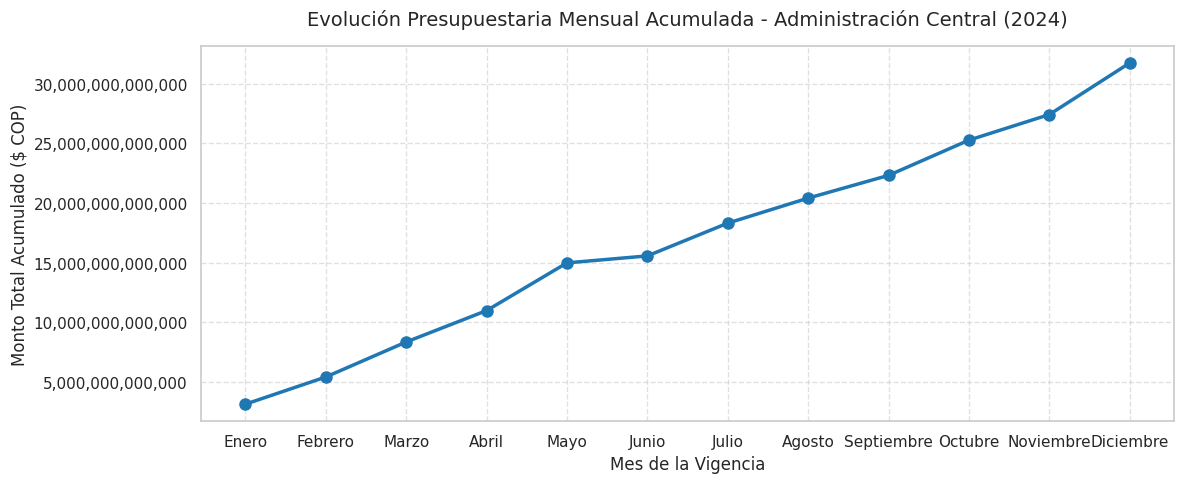

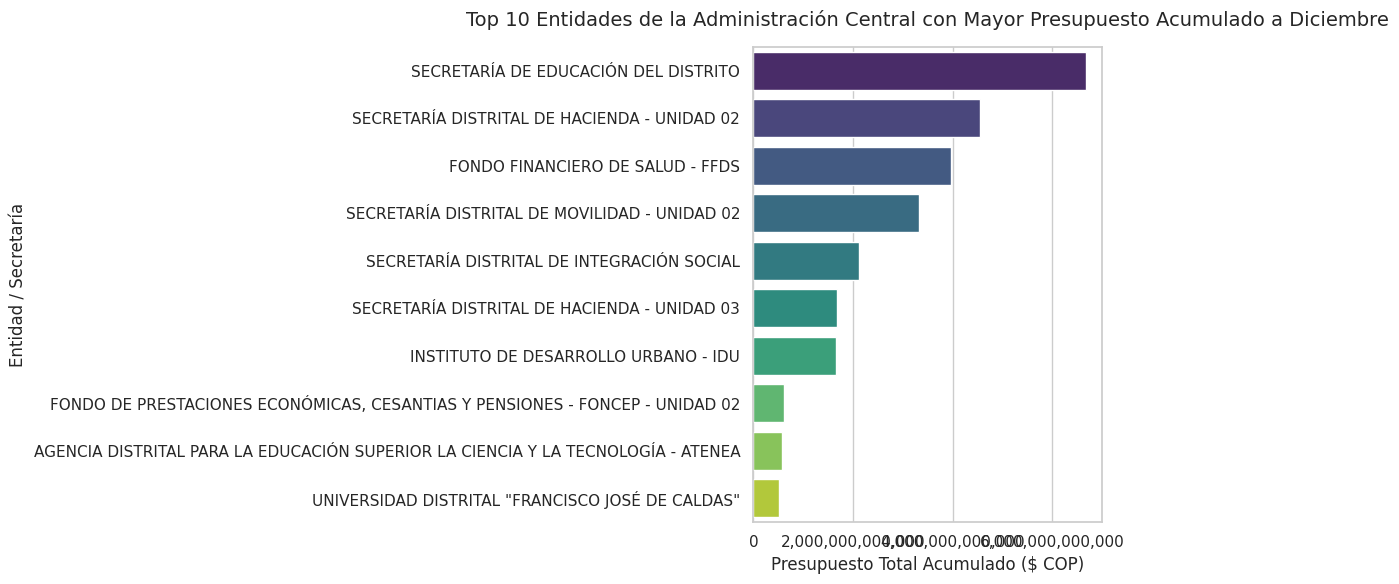

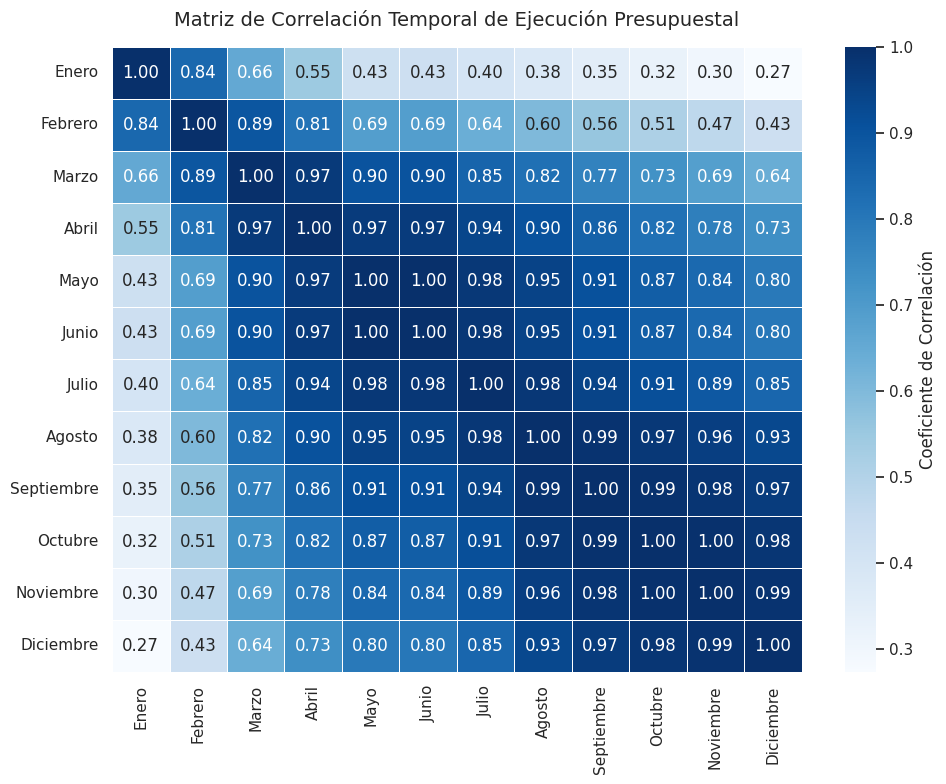


📊 --- RESUMEN ESTADÍSTICO EXPLORATORIO ---
• Número de transacciones presupuestales analizadas (filas): 13770
• Número de entidades/secretarías mapeadas: 52
• Presupuesto total ejecutado/acumulado al cierre de año (Diciembre): $31,758,133,276,038.00 COP


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

# Cargar el archivo ya limpio
try:
    df = pd.read_csv('datos_presupuesto_limpios.csv', sep=';', encoding='utf-8')
    print("✅ Dataset cargado correctamente para el EDA.")
except FileNotFoundError:
    print("❌ Sube el archivo 'datos_presupuesto_limpios.csv' al panel izquierdo de Colab antes de continuar.")

# Definición de las variables numéricas de tiempo
meses = ['Enero', 'Febrero', 'Marzo', 'Abril', 'Mayo', 'Junio', 'Julio', 'Agosto', 'Septiembre', 'Octubre', 'Noviembre', 'Diciembre']

# COMPORTAMIENTO TEMPORAL DEL PRESUPUESTO DISTRITAL

# Agrupamos los datos para ver cómo crece el gasto acumulado mes a mes a nivel ciudad
gasto_mensual_total = df[meses].sum()

plt.figure(figsize=(12, 5))
plt.plot(meses, gasto_mensual_total, marker='o', color='#1f77b4', linewidth=2.5, markersize=8)
plt.title('Evolución Presupuestaria Mensual Acumulada - Administración Central (2024)', fontsize=14, pad=15)
plt.xlabel('Mes de la Vigencia', fontsize=12)
plt.ylabel('Monto Total Acumulado ($ COP)', fontsize=12)
plt.ticklabel_format(style='plain', axis='y')
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:,}".format(int(x))))
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

# TOP 10 ENTIDADES CON MAYOR ASIGNACIÓN PRESUPUESTAL
# Sumamos el mes final (Diciembre) para conocer el presupuesto anualizado total de cada entidad
presupuesto_por_entidad = df.groupby('Nombre de la Entidad')['Diciembre'].sum().sort_values(ascending=False).head(10)

plt.figure(figsize=(12, 6))
sns.barplot(
    x=presupuesto_por_entidad.values,
    y=presupuesto_por_entidad.index,
    hue=presupuesto_por_entidad.index,
    palette='viridis',
    legend=False
)
plt.title('Top 10 Entidades de la Administración Central con Mayor Presupuesto Acumulado a Diciembre', fontsize=14, pad=15)
plt.xlabel('Presupuesto Total Acumulado ($ COP)', fontsize=12)
plt.ylabel('Entidad / Secretaría', fontsize=12)
plt.gca().xaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:,}".format(int(x))))
plt.tight_layout()
plt.show()

# MATRIZ DE CORRELACIÓN ENTRE PERIODOS MENSUALES
matriz_corr = df[meses].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(matriz_corr, annot=True, cmap='Blues', fmt=".2f", linewidths=.5, cbar_kws={"label": "Coeficiente de Correlación"})
plt.title('Matriz de Correlación Temporal de Ejecución Presupuestal', fontsize=14, pad=15)
plt.tight_layout()
plt.show()

# CONCLUSIONES ESTADÍSTICAS DEL EDA
print("\n📊 --- RESUMEN ESTADÍSTICO EXPLORATORIO ---")
print(f"• Número de transacciones presupuestales analizadas (filas): {df.shape[0]}")
print(f"• Número de entidades/secretarías mapeadas: {df['Nombre de la Entidad'].nunique()}")
print(f"• Presupuesto total ejecutado/acumulado al cierre de año (Diciembre): ${df['Diciembre'].sum():,.2f} COP")